In [1]:
from langgraph.graph import StateGraph,START,MessagesState
from langchain_groq import ChatGroq
from dotenv import load_dotenv

In [2]:
load_dotenv()

True

In [3]:
model=ChatGroq(model="openai/gpt-oss-20b",temperature=0)

In [4]:
def call_node(state:MessagesState):
    response=model.invoke(state["messages"])
    return {"messages":[response]}

In [5]:
builder=StateGraph(MessagesState)
builder.add_node("call_node",call_node)
builder.add_edge(START,"call_node")

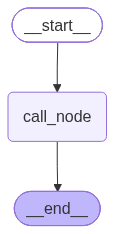

In [6]:
graph=builder.compile()
graph

In [7]:
graph.invoke({"messages":[{"role":"user","content":"hii! my name is nitish"}]})

{'messages': [HumanMessage(content='hii! my name is nitish', additional_kwargs={}, response_metadata={}, id='e8ea6243-e9a6-4eae-a064-b63f06de2b41'),
  AIMessage(content='Hello Nitish! 👋 How can I help you today?', additional_kwargs={'reasoning_content': 'User says "hii! my name is nitish". They are greeting. We should respond politely, ask how we can help.'}, response_metadata={'token_usage': {'completion_tokens': 50, 'prompt_tokens': 79, 'total_tokens': 129, 'completion_time': 0.050331959, 'completion_tokens_details': {'reasoning_tokens': 28}, 'prompt_time': 0.003828077, 'prompt_tokens_details': None, 'queue_time': 0.31557253, 'total_time': 0.054160036}, 'model_name': 'openai/gpt-oss-20b', 'system_fingerprint': 'fp_9b8528b477', 'service_tier': 'on_demand', 'finish_reason': 'stop', 'logprobs': None, 'model_provider': 'groq'}, id='lc_run--01a1529d-cf29-7522-9e8e-8c1b7da6ec77-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 79, 'output_tokens': 50, 'total_tokens'

In [8]:
graph.invoke({"messages":[{"role":"user","content":"what is my name?"}]})

{'messages': [HumanMessage(content='what is my name?', additional_kwargs={}, response_metadata={}, id='38d04993-94fa-44be-bc5b-1e65b9a35980'),
  AIMessage(content='I’m not sure what your name is—could you let me know?', additional_kwargs={'reasoning_content': 'The user asks "what is my name?" We don\'t know their name. We should respond politely, maybe ask for clarification. According to policy, we should not guess. So respond: "I don\'t know your name. Could you tell me?"'}, response_metadata={'token_usage': {'completion_tokens': 74, 'prompt_tokens': 76, 'total_tokens': 150, 'completion_time': 0.076857503, 'completion_tokens_details': {'reasoning_tokens': 50}, 'prompt_time': 0.004440812, 'prompt_tokens_details': None, 'queue_time': 0.208794979, 'total_time': 0.081298315}, 'model_name': 'openai/gpt-oss-20b', 'system_fingerprint': 'fp_e23fc997ca', 'service_tier': 'on_demand', 'finish_reason': 'stop', 'logprobs': None, 'model_provider': 'groq'}, id='lc_run--01a1529e-719a-7e93-a832-fd05ac

In [9]:
def call_node(state:MessagesState):
    response=model.invoke(state["messages"])
    return {"messages":[response]}

In [10]:
builder=StateGraph(MessagesState)
builder.add_node("call_node",call_node)
builder.add_edge(START,"call_node")

In [11]:
from langgraph.checkpoint.memory import InMemorySaver
checkpointer=InMemorySaver()
graph=builder.compile(checkpointer=checkpointer)

In [13]:
config={"configurable":{"thread_id":"thread-1"}}

In [14]:
graph.invoke({"messages":[{"role":"user","content":"hii! my name is nitish"}]},config)

{'messages': [HumanMessage(content='hii! my name is nitish', additional_kwargs={}, response_metadata={}, id='bcccc68b-d9ee-4c96-9259-8b7f858e16f4'),
  AIMessage(content='Hello Nitish! 👋 How can I help you today?', additional_kwargs={'reasoning_content': 'User says "hii! my name is nitish". They are greeting. We should respond politely, ask how we can help.'}, response_metadata={'token_usage': {'completion_tokens': 50, 'prompt_tokens': 79, 'total_tokens': 129, 'completion_time': 0.051803116, 'completion_tokens_details': {'reasoning_tokens': 28}, 'prompt_time': 0.003865405, 'prompt_tokens_details': None, 'queue_time': 0.336671771, 'total_time': 0.055668521}, 'model_name': 'openai/gpt-oss-20b', 'system_fingerprint': 'fp_3826805fb8', 'service_tier': 'on_demand', 'finish_reason': 'stop', 'logprobs': None, 'model_provider': 'groq'}, id='lc_run--01a152a2-2a01-7ae2-b601-f46cdc381c93-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 79, 'output_tokens': 50, 'total_tokens

In [15]:
graph.invoke({"messages":[{"role":"user","content":"what is my name?"}]},config)

{'messages': [HumanMessage(content='hii! my name is nitish', additional_kwargs={}, response_metadata={}, id='bcccc68b-d9ee-4c96-9259-8b7f858e16f4'),
  AIMessage(content='Hello Nitish! 👋 How can I help you today?', additional_kwargs={'reasoning_content': 'User says "hii! my name is nitish". They are greeting. We should respond politely, ask how we can help.'}, response_metadata={'token_usage': {'completion_tokens': 50, 'prompt_tokens': 79, 'total_tokens': 129, 'completion_time': 0.051803116, 'completion_tokens_details': {'reasoning_tokens': 28}, 'prompt_time': 0.003865405, 'prompt_tokens_details': None, 'queue_time': 0.336671771, 'total_time': 0.055668521}, 'model_name': 'openai/gpt-oss-20b', 'system_fingerprint': 'fp_3826805fb8', 'service_tier': 'on_demand', 'finish_reason': 'stop', 'logprobs': None, 'model_provider': 'groq'}, id='lc_run--01a152a2-2a01-7ae2-b601-f46cdc381c93-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 79, 'output_tokens': 50, 'total_tokens

In [16]:
snap=graph.get_state(config)
vals=snap.values
for m in vals.get("messages",[]):
    print("--",type(m).__name__,":",m.content)

-- HumanMessage : hii! my name is nitish
-- AIMessage : Hello Nitish! 👋 How can I help you today?
-- HumanMessage : what is my name?
-- AIMessage : Your name is Nitish.
